# Pivot switching: phase field (Fig. 4)

This example repeats [`psc_fig3_kpp_fisher`](psc_fig3_kpp_fisher.ipynb) with a cubic reaction,
where the fold reaches two levels below the truncation instead of one.

$$\frac{d\varphi_i}{dt}=\varphi_{i-1}-2\varphi_i+\varphi_{i+1}
-(\varphi_i-1)(\varphi_i+\beta)(\varphi_i+1),\qquad \beta=-0.2,\quad\varphi_i=\varphi_{i+8}$$

Eight sites on a ring. Same three assembly steps as
[`psc_fig3_kpp_fisher`](psc_fig3_kpp_fisher.ipynb), but with a **cubic** right-hand side: the
reaction has on-site order $M=3$, where the logistic one had $2$.

Reproduces Fig. 4 of [arXiv:2411.16233](https://arxiv.org/abs/2411.16233); every equation and
figure number here is that paper's, and $\varphi(0)$ is its Eq. (22).

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines Carleman, PSC, pivot, fold, bra, ket and
  the symbols $P$, $A$ and $\boldsymbol\Phi$.
- [`psc_carleman`](../tutorials/04_basis/psc_carleman.ipynb) constructs `PSCarlemanBasis`.
:::

| panel | run |
|---|---|
| (a) | the nonlinear ODE, integrated directly |
| (b) | Carleman, truncation order 3 |
| (c, d) | PSC at orders 3 and 5, pivot fixed at $s=-1$ |
| (e, f) | the same, pivot switched from $\varphi(0)$ to $-1$ at $t=2.9$ |

## Two misprints in the paper

**First, the reaction sign.** Eq. (21) prints $+(\varphi_i-1)(\varphi_i+\beta)(\varphi_i+1)$. Three
of the paper's own statements fail as printed and hold negated:

| the paper states | as printed | negated |
| --- | --- | --- |
| "if $\beta<0$, $\varphi=-1$ is stable" | $R'(-1)=+2.4$, unstable | $-2.4$, stable |
| "the solution evolved to $\varphi=-1$" | $\varphi(5)\to+0.20$, which is $-\beta$ | $\to-0.98$ |
| Eq. (22) is an equilibrium at $\beta=0$ | not stationary | stationary |

**Second, which pivot.** The Fig. 4 caption fixes $s=1$, the body text $s=-1$. This notebook
follows the body, because $V(-1)-V(1)=\tfrac43\beta<0$, so $-1$ is the deeper well and the
attractor the field reaches.

> **Requires Linux or macOS and several cores.** The assembly hands one column per worker through a
> `fork`-based process pool, which Windows does not provide.


In [1]:
import itertools
import os
from collections import defaultdict
from concurrent.futures import ProcessPoolExecutor
from functools import cache, partial
from multiprocessing import get_context

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib import cm
from scipy.integrate import solve_ivp
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply

from lin_ode.basis import CarlemanBasis, PSCarlemanBasis, TruncatedBasisSet
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem

N, ORDER = 8, 3  # ring sites; on-site polynomial order M of the right-hand side: the cubic reaction
T_END, SWITCH, FRAMES = 5.0, 2.9, 501
WORKERS = os.cpu_count() or 4  # step 3 hands one column per worker
BETA = sp.Rational(-1, 5)
PROFILE = np.array([-0.90, -0.56, 0.56, 0.90, 0.90, 0.56, -0.56, -0.90])  # phi(t=0), Eq. (22)
PIVOT = sp.IndexedBase("s")  # per-site pivot; PIVOT[i] is the pivot at site i
FIXED_PIVOT = {k: -1.0 for k in range(N)}  # s = -1, the attractor when beta < 0
INITIAL_PIVOT = {k: float(PROFILE[k]) for k in range(N)}  # s = phi(0)
times = np.linspace(0, T_END, FRAMES)


def rhs(u: sp.IndexedBase, i: sp.Idx) -> sp.Expr:
    """Eq. (21), reaction in Allen-Cahn sign (see the note above)."""
    lap = u[sp.Mod(i - 1, N)] - 2 * u[i] + u[sp.Mod(i + 1, N)]
    return sp.expand(lap - (u[i] - 1) * (u[i] + BETA) * (u[i] + 1))


def rhs_numpy(u: np.ndarray, beta: float = float(BETA)) -> np.ndarray:
    """The same right-hand side, on a whole profile."""
    lap = np.roll(u, 1) - 2 * u + np.roll(u, -1)
    return lap - (u - 1) * (u + beta) * (u + 1)


print(f"f_i = {rhs(sp.IndexedBase('u'), sp.Idx('i', (0, N - 1)))}")
print(f"M = {ORDER}, so the generator raises a monomial by at most {ORDER - 1}")

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors


f_i = u[Mod(i + 1, 8)] + u[Mod(i + 7, 8)] - u[i]**3 + u[i]**2/5 - u[i] - 1/5
M = 3, so the generator raises a monomial by at most 2


---

> **Check — which reaction sign**, not a step of the method. Two tests: is $\varphi=\pm1$ stable,
> and is $\varphi(0)$ stationary at $\beta=0$? Only one sign passes both.

In [2]:
phi = sp.Symbol("phi")
for sign, name in ((+1, "as printed"), (-1, "negated")):
    slopes = [
        sp.diff(sign * (phi - 1) * (phi + BETA) * (phi + 1), phi).subs(phi, p)
        for p in (-1, 1)
    ]
    verdict = "stable" if all(v < 0 for v in slopes) else "UNSTABLE"
    print(f"{name:11s}: dR/dphi at -1, +1 = {str(slopes[0]):>6}, {str(slopes[1]):>6}"
          f"  ->  phi=+-1 {verdict}")

lap = np.roll(PROFILE, 1) - 2 * PROFILE + np.roll(PROFILE, -1)
for sign, name in ((+1, "as printed"), (-1, "negated")):
    for dz2 in (1.0, 2.0):
        residual = np.abs(lap / dz2 + sign * (PROFILE - 1) * PROFILE * (PROFILE + 1)).max()
        print(f"{name:11s} dz^2={dz2}: max|d(phi)/dt| at phi(0), beta=0 = {residual:.4f}")

as printed : dR/dphi at -1, +1 =   12/5,    8/5  ->  phi=+-1 UNSTABLE
negated    : dR/dphi at -1, +1 =  -12/5,   -8/5  ->  phi=+-1 stable
as printed  dz^2=1.0: max|d(phi)/dt| at phi(0), beta=0 = 1.1644
as printed  dz^2=2.0: max|d(phi)/dt| at phi(0), beta=0 = 0.7744
negated     dz^2=1.0: max|d(phi)/dt| at phi(0), beta=0 = 0.3956
negated     dz^2=2.0: max|d(phi)/dt| at phi(0), beta=0 = 0.0056


Only the negated sign has $\varphi=\pm1$ stable *and* leaves $\varphi(0)$ stationary. The second
test passes at $\Delta z^2=2$, within the rounding of the quoted values.

This notebook keeps the stated $\Delta z^2=1$, which reproduces Fig. 4(a). At $2$ the field has
not reached $-1$ by $t=5$.

## Assembly by shape

The three reductions are unchanged from [`psc_fig3_kpp_fisher`](psc_fig3_kpp_fisher.ipynb):
sparsity per column, shape classes on the ring, one call per shape.

Only the right-hand side differs, and that costs one thing. The generator now raises a power by up
to $M-1=2$ instead of $1$.

So a column reaches further, and the fold lands on a larger sub-monomial box: two levels down
instead of one.

<!-- figure: psc-fold (docs/make_figures.py) -->

> **Why "two levels".**
>
> $$u^{P+1}\;\longmapsto\;-\sum_{m=0}^{P}\binom{P+1}{m}(-s)^{P+1-m}u^{m}$$
>
> ![The PSC fold: the weights it leaves on each retained basis state](../figures/psc-fold.png)
>
> A gold box holds the weight the fold leaves on the state above it; the columns are the four
> retained states at $P=3$.
>
> | row | the monomial above the degree | reached by |
> |---|---|---|
> | $u^{4}$ | one level above | any right-hand side, $M\ge2$ |
> | $u^{5}$ | two levels above | only an $M=3$ term |
>
> Same four states, different weights. The second row is what this notebook pays for, and it does
> not arise in [`psc_fig3_kpp_fisher`](psc_fig3_kpp_fisher.ipynb).


### 1. The sparsity pattern of a column

Unchanged from [`psc_fig3_kpp_fisher`](psc_fig3_kpp_fisher.ipynb), with the wider reach noted above.

In [3]:
def shift_powers(powers: dict[int, int], *moves: tuple[int, int]) -> StateLabel:
    """`powers` with each (site, delta) applied, back as a sorted (site, power) tuple."""
    moved = dict(powers)
    for site, delta in moves:
        moved[site] = moved.get(site, 0) + delta
    return tuple(sorted((site, power) for site, power in moved.items() if power > 0))


def find_reachable_monomials(ket: StateLabel) -> set[StateLabel]:
    """Monomials the generator can send `ket` to, before any truncation."""
    powers = {int(site): int(power) for site, power in ket}
    targets = {shift_powers(powers, (site, delta))
               for site in powers for delta in range(-1, ORDER)}
    targets |= {shift_powers(powers, (site, -1), ((site + step) % N, 1))
                for site in powers for step in (-1, 1)}
    return targets


def find_bras(ket: StateLabel, degree: int) -> list[StateLabel]:
    """Bras that can pick up weight from `ket`: each target, and everything a fold puts under it."""
    bras = set()
    for target in find_reachable_monomials(ket):
        for lowered in itertools.product(*(range(power + 1) for _, power in target)):
            if sum(lowered) <= degree:  # every sub-monomial of this target, in the basis
                bras.add(tuple((site, p) for (site, _), p in zip(target, lowered) if p > 0))
    return sorted(bras)

In [4]:
ket = ((0, 1), (1, 1))  # |phi_0 phi_1>
print(f"reaches {len(find_reachable_monomials(ket))} monomials")
print(f"folding onto {len(find_bras(ket, 3))} bras at P=3, out of {len(CarlemanBasis(N, 3))} states")
print("phi_0^4 folds to:", sp.expand(PSCarlemanBasis(N, 3, PIVOT).truncation_rule((0, 4))))

reaches 11 monomials
folding onto 14 bras at P=3, out of 165 states
phi_0^4 folds to: -CarlemanState()*s[0]**4 + 4*s[0]**3*CarlemanState((0, 1)) - 6*s[0]**2*CarlemanState((0, 2)) + 4*s[0]*CarlemanState((0, 3))


### 2. Shape classes under the ring symmetry

Unchanged: kets related by a rotation or reflection of the ring share a column.

In [5]:
def find_reference_ket(ket: StateLabel) -> tuple[StateLabel, dict[int, int]]:
    """The one ket standing for `ket`'s shape, and the site map from it back to `ket`."""

    def image(relabel: tuple[int, int]) -> StateLabel:
        offset, sign = relabel
        return tuple(sorted(((offset + sign * int(s)) % N, int(p)) for s, p in ket))

    relabels = [(offset, sign) for offset in range(N) for sign in (1, -1)]  # sigma(i) = offset + sign*i
    offset, sign = min(relabels, key=image)          # least image: arbitrary but fixed
    back = {(offset + sign * site) % N: site for site in range(N)}  # sigma read backwards
    return image((offset, sign)), back

In [6]:
demo_basis = CarlemanBasis(N, 3)
shapes: defaultdict[StateLabel, list[StateLabel]] = defaultdict(list)
for flat in range(len(demo_basis)):
    ket = demo_basis.structured_idx_of_flat_index(flat)
    if ket:  # the vacuum is its own trivial case
        reference, _ = find_reference_ket(ket)
        shapes[reference].append(ket)

print(f"{len(demo_basis) - 1} kets share {len(shapes)} shapes, for instance")
for reference in (((0, 1),), ((0, 1), (1, 1)), ((0, 1), (3, 2))):
    print(f"   {str(reference):20s} <- {len(shapes[reference])} kets: {shapes[reference][:3]} ...")

164 kets share 16 shapes, for instance
   ((0, 1),)            <- 8 kets: [((0, 1),), ((1, 1),), ((2, 1),)] ...
   ((0, 1), (1, 1))     <- 8 kets: [((0, 1), (1, 1)), ((0, 1), (7, 1)), ((1, 1), (2, 1))] ...
   ((0, 1), (3, 2))     <- 16 kets: [((0, 2), (3, 1)), ((0, 2), (5, 1)), ((0, 1), (3, 2))] ...


### 3. One `lin_ode` call per shape

Unchanged, including the pivot relabelling. Both substitutions are required; omitting the pivot one
is correct only for a uniform pivot.

In [7]:
@cache  # one operator per basis, per process
def get_koopman_matrix(basis: TruncatedBasisSet) -> OperatorMatrix:
    """`lin_ode`'s symbolic <bra| L |ket> for Eq. (21) on `basis`."""
    u, i = sp.IndexedBase("u"), sp.Idx("i", (0, N - 1))
    ode = OrdinaryDifferentialSystem.from_sympy(rhs(u, i), u, (i,))
    return OperatorMatrix(basis, Koopman().create_operator(ode))


def compute_column(
    basis: TruncatedBasisSet, ket: StateLabel
) -> dict[StateLabel, sp.Expr]:
    """{bra: value} for one ket: the single `lin_ode` call, and the pool's unit of work."""
    bras = find_bras(ket, basis.degree)
    column = get_koopman_matrix(basis)[bras, [ket]]  # one call returns the whole column
    return {bra: column[row, 0] for row, bra in enumerate(bras) if column[row, 0] != 0}


def map_columns(
    basis: TruncatedBasisSet, kets: list[StateLabel]
) -> list[dict[StateLabel, sp.Expr]]:
    """`compute_column` over `kets`, one column per worker.

    Needs `fork`, so Linux or macOS: a worker resolves `compute_column` by name, which a
    forked child already has and a spawned one does not -- it re-imports `__main__`, and a
    notebook's `__main__` is not importable.
    """
    with ProcessPoolExecutor(WORKERS, mp_context=get_context("fork")) as pool:
        return list(pool.map(partial(compute_column, basis), kets, chunksize=1))


def relabel_column(
    column: dict[StateLabel, sp.Expr], back: dict[int, int]
) -> dict[StateLabel, sp.Expr]:
    """A reference ket's column moved onto its shape-mate: bras and pivot symbols alike.

    s[i] labels a site, so it has to travel with the relabelling. Move only the bras and a
    per-site pivot silently ends up on the wrong sites -- a uniform pivot would not notice.
    """
    pivots = {PIVOT[site]: PIVOT[image] for site, image in back.items()}
    moved = {}
    for bra, value in column.items():
        moved[tuple(sorted((back[s], p) for s, p in bra))] = sp.sympify(value).xreplace(pivots)
    return moved


def build_entries_by_shape(
    basis: TruncatedBasisSet,
) -> tuple[dict[tuple[int, int], sp.Expr], int]:
    """Symbolic {(bra, ket): value} for the whole basis, and how many columns it cost."""
    kets = [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]
    shape_of = {ket: find_reference_ket(ket) for ket in kets if ket}  # ket -> (reference, back)
    references = list(dict.fromkeys(reference for reference, _ in shape_of.values()))
    columns = dict(zip(references, map_columns(basis, references)))

    entries: dict[tuple[int, int], sp.Expr] = {}
    for ket_flat, ket in enumerate(kets):
        if not ket:
            continue  # every term carries a d/dphi_s, so the vacuum column is zero
        reference, back = shape_of[ket]
        for bra, value in relabel_column(columns[reference], back).items():
            entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value
    return entries, len(references)


def build_matrix(
    entries: dict[tuple[int, int], sp.Expr],
    dim: int,
    pivot: dict[int, float] = {},  # noqa: B006 - read-only
) -> csc_matrix:
    """A for dPhi/dt = A Phi: substitute s[k] -> pivot[k], cast to float, transpose."""
    subs = {PIVOT[k]: sp.Float(v) for k, v in pivot.items()}
    rows = [row for row, _ in entries]
    cols = [col for _, col in entries]
    data = [float(sp.sympify(value).xreplace(subs)) for value in entries.values()]
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()

---

> **Check — relabelling is exact**, not a step of the method. A column moved from its reference must
> equal one computed from scratch, pivot symbols included.


In [8]:
check_basis = PSCarlemanBasis(N, 3, PIVOT)
check_ket = ((3, 1), (4, 1))
reference, back = find_reference_ket(check_ket)

moved = relabel_column(compute_column(check_basis, reference), back)
direct = compute_column(check_basis, check_ket)
assert moved.keys() == direct.keys(), "relabelling landed on different bras"
assert all(sp.simplify(moved[bra] - direct[bra]) == 0 for bra in direct), "values disagree"
print(f"column of {check_ket} reproduced by relabelling its reference {reference}")

column of ((3, 1), (4, 1)) reproduced by relabelling its reference ((0, 1), (1, 1))


## Assembling the generators

One assembly per basis; the pivot stays symbolic, so one assembly serves both pivots.

⚠️ **Around six minutes** on 10 cores, almost all of it the $P=5$ assembly. Cubic folds reach two
levels down, so the 102 columns of that assembly carry boxes of several hundred elements through
`sympy`.

In [9]:
carleman_basis = CarlemanBasis(N, 3)  # the paper compares against K = 3 only
carleman_entries, columns = build_entries_by_shape(carleman_basis)
carleman_matrix = build_matrix(carleman_entries, len(carleman_basis))
print(f"Carleman K=3: dim={len(carleman_basis)} nnz={carleman_matrix.nnz} "
      f"from {columns} lin_ode columns")

psc_bases = {p: PSCarlemanBasis(N, p, PIVOT) for p in (3, 5)}
psc_entries = {}
for p, basis in psc_bases.items():
    psc_entries[p], columns = build_entries_by_shape(basis)
    print(f"PSC P={p}: dim={len(basis)} entries={len(psc_entries[p])} "
          f"from {columns} lin_ode columns")


def psc_matrix(p: int, pivot: dict[int, float]) -> csc_matrix:
    """A at degree `p` about `pivot` -- a substitution; the symbolic work is already done."""
    return build_matrix(psc_entries[p], len(psc_bases[p]), pivot)


# label -> (basis, segments); a second segment switches the pivot at t = SWITCH
runs = {
    "Carleman K=3": (carleman_basis, [(T_END, carleman_matrix)]),
    "PSC P=3, s=-1": (psc_bases[3], [(T_END, psc_matrix(3, FIXED_PIVOT))]),
    "PSC P=5, s=-1": (psc_bases[5], [(T_END, psc_matrix(5, FIXED_PIVOT))]),
    "PSC P=3, switched": (psc_bases[3], [(SWITCH, psc_matrix(3, INITIAL_PIVOT)),
                                         (T_END, psc_matrix(3, FIXED_PIVOT))]),
    "PSC P=5, switched": (psc_bases[5], [(SWITCH, psc_matrix(5, INITIAL_PIVOT)),
                                         (T_END, psc_matrix(5, FIXED_PIVOT))]),
}
for label, (basis, segments) in runs.items():
    print(f"{label:20s} dim={len(basis):5d}  nnz={segments[-1][1].nnz:6d}  "
          f"{len(segments)} segment(s)")

Carleman K=3: dim=165 nnz=1324 from 16 lin_ode columns


PSC P=3: dim=165 entries=2632 from 16 lin_ode columns


PSC P=5: dim=1287 entries=72928 from 102 lin_ode columns


Carleman K=3         dim=  165  nnz=  1324  1 segment(s)
PSC P=3, s=-1        dim=  165  nnz=  2632  1 segment(s)
PSC P=5, s=-1        dim= 1287  nnz= 72928  1 segment(s)
PSC P=3, switched    dim=  165  nnz=  2632  2 segment(s)
PSC P=5, switched    dim= 1287  nnz= 72928  2 segment(s)


## Segment-wise propagation

$$\boldsymbol\Phi(t)=e^{At}\boldsymbol\Phi(0)$$

- one `expm_multiply` per segment, nothing to tune
- a pivot switch is the next segment's matrix; $\boldsymbol\Phi$ crosses unchanged


In [10]:
def evolve(segments: list[tuple[float, csc_matrix]], initial: np.ndarray) -> np.ndarray:
    """Phi(t) on `times`, exponentiating each (t_to, A) segment in turn."""
    vector, t_from, blocks = initial, 0.0, [initial[None, :]]
    for t_to, matrix in segments:
        num = 1 + round((t_to - t_from) / T_END * (FRAMES - 1))
        block = expm_multiply(matrix, vector, start=0, stop=t_to - t_from, num=num, endpoint=True)
        blocks.append(block[1:])  # [1:]: t_from is already in
        vector, t_from = block[-1], t_to
    return np.concatenate(blocks)


def solve(basis: TruncatedBasisSet, segments: list[tuple[float, csc_matrix]]) -> np.ndarray:
    """phi_i(t): evaluate every monomial at the profile, evolve, slice the degree-1 rows out."""
    monomials = [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]
    initial = np.array([np.prod([PROFILE[int(s)] ** int(p) for s, p in m]) for m in monomials])
    rows = [basis.flat_index_of_basis_function(basis.state_type((k, 1))) for k in range(N)]
    trajectory = evolve(segments, initial)[:, rows]  # phi_i *is* a basis element: it is a slice
    assert len(trajectory) == FRAMES, "segment grids do not add up to the time grid"
    return trajectory


solutions = {label: solve(basis, segments) for label, (basis, segments) in runs.items()}
print(f"{len(solutions)} linear solutions, {FRAMES} frames each")

5 linear solutions, 501 frames each


## Direct nonlinear reference

The nonlinear ODE integrated directly. The reference shares no code with the linearization.


In [11]:
nonlinear = solve_ivp(
    lambda _, u: rhs_numpy(u), (0.0, T_END), PROFILE, t_eval=times,
    method="LSODA", rtol=1e-10, atol=1e-12,
)
assert nonlinear.success, nonlinear.message
classical = nonlinear.y.T
solutions = {"classical": classical} | solutions

for label, trajectory in solutions.items():
    print(f"{label:20s} max|phi| = {np.abs(trajectory).max():10.4g}   "
          f"phi(5) = {trajectory[-1].mean():10.4f}   "
          f"max deviation from classical = {np.abs(trajectory - classical).max():.4g}")

classical            max|phi| =     0.9925   phi(5) =    -0.9843   max deviation from classical = 0
Carleman K=3         max|phi| =  1.782e+04   phi(5) = -15420.9079   max deviation from classical = 1.782e+04
PSC P=3, s=-1        max|phi| =      1.826   phi(5) =    -1.0000   max deviation from classical = 1.385
PSC P=5, s=-1        max|phi| =      3.348   phi(5) =    -0.9999   max deviation from classical = 2.575
PSC P=3, switched    max|phi| =      0.998   phi(5) =    -0.9968   max deviation from classical = 0.341
PSC P=5, switched    max|phi| =     0.9888   phi(5) =    -0.9780   max deviation from classical = 0.2554


## Six-panel comparison with the paper

One line per sampled time, coloured by $t$; black is $t=0$. Panels read down the columns, as in the
paper.

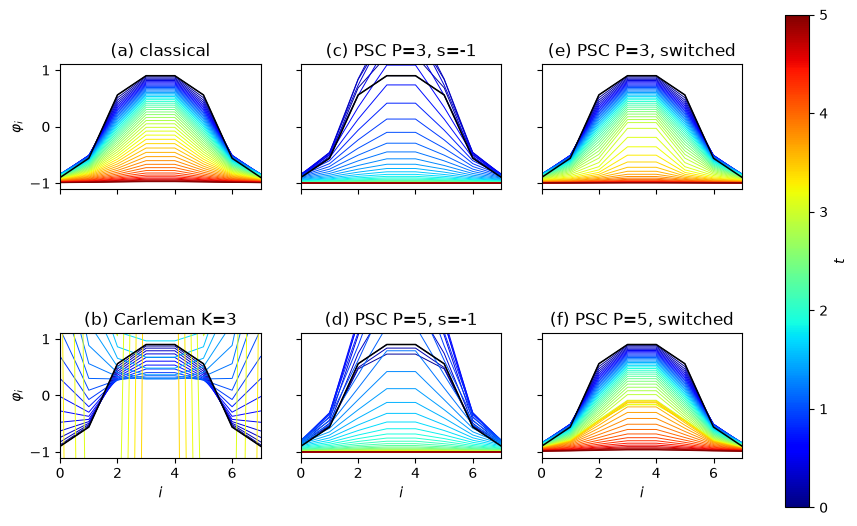

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharex=True, sharey=True)
for letter, ax, (label, trajectory) in zip("abcdef", axes.T.ravel(), solutions.items()):
    for k in range(0, FRAMES, 10):
        ax.plot(range(N), trajectory[k], color=cm.jet(times[k] / T_END), lw=0.7)
    ax.plot(range(N), trajectory[0], "k-", lw=1.1)
    ax.set(title=f"({letter}) {label}", xlim=(0, N - 1), ylim=(-1.1, 1.1))
    ax.set_box_aspect(0.62)
for row in (0, 1):
    axes[row, 0].set_ylabel(r"$\varphi_i$")
for col in range(3):
    axes[1, col].set_xlabel("$i$")
fig.colorbar(cm.ScalarMappable(cmap=cm.jet, norm=plt.Normalize(0, T_END)),
             ax=axes, label="$t$")
plt.show()


| panel | what it shows |
|---|---|
| **(b)** | Carleman order 3 runs away: $\max\lvert\varphi\rvert\approx1.8\times10^{4}$ |
| **(c, d)** | pivot fixed at $-1$, and the curves **leave the panel**: $\max\lvert\varphi\rvert=1.83$ and $3.35$ against a $\pm1.1$ axis |
| **(e, f)** | pivot switched once at $t=2.9$: follows the exact curve |

Note (c) against (d): at a fixed pivot the field starts far from $-1$, and **order 5 is worse than
order 3**.

A higher truncation order does not compensate for a badly placed pivot. The higher order only adds
more terms that can be wrong.


## Cubic versus quadratic right-hand sides

Step 1 folds with the *full* Taylor polynomial. A cheaper rule exists: impose $(u-s)^m=0$ and keep
whatever lands in the basis. That rule agrees with the full fold **only** at $m=P+1$:

In [13]:
u, s, P = *sp.symbols("u s"), 3
for m in (P + 1, P + 2):
    taylor = sum(
        sp.diff(u**m, u, j).subs(u, s) / sp.factorial(j) * (u - s) ** j
        for j in range(P + 1)
    )
    single = -sum(sp.binomial(m, b) * (-s) ** (m - b) * u**b for b in range(P + 1))
    print(f"m = P+{m - P}:  agree? {sp.expand(taylor - single) == 0}")
    if sp.expand(taylor - single) != 0:
        print(f"   Taylor          {sp.expand(taylor)}")
        print(f"   single relation {sp.expand(single)}")

m = P+1:  agree? True
m = P+2:  agree? False
   Taylor          -4*s**5 + 15*s**4*u - 20*s**3*u**2 + 10*s**2*u**3
   single relation s**5 - 5*s**4*u + 10*s**3*u**2 - 10*s**2*u**3


An order-$M$ right-hand side reaches $m=P+M-1$:

| rule | reach | tells the two apart? |
|---|---|---|
| quadratic | $m=P+1$ | no, and this is the paper's Eq. 16 |
| cubic | $m=P+2$ | yes |

The extra level is what the cubic reaction needs, and where the two rules first differ.

`lin_ode` implements the full Taylor projection; see
[`psc_carleman`](../tutorials/04_basis/psc_carleman.ipynb).

---

[← Pivot switching: KPP–Fisher](psc_fig3_kpp_fisher.ipynb) · [Notebook index](../README.md) · [Pivot switching: logistic →](psc_logistic_switching.ipynb)